# borg-queen 00 · The factor risk model

A point-in-time factor model over vinculum's 1,000 largest companies: the market, 12 Fama-French
sectors and 8 styles. Exposures are set at each month end from neural-processor signals; each
day's returns are regressed on the latest month end's exposures before that day; factor
covariance is an EWMA with a volatility-regime adjustment; specific risk is an EWMA of each
name's residuals, shrunk toward its size decile. This notebook reads the model built by
`queen build` and tests it on portfolios made from its own exposures; `01_optimizer.ipynb` uses
it to build portfolios.

1. what is built
2. exposures
3. factor returns
4. covariance
5. specific risk
6. forecast against realized risk
7. attribution
8. the built-in checks

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from borg_queen import FACTORS, STYLES, RiskModel, bias_stat
from subspace_probe import style, timed

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(190)
rm = RiskModel()
st = rm.status()
print({k: st[k] for k in ("built_at", "first_month", "last_month", "days", "median_r2")})
print(st["settings"])
months = rm.months()
last = months[-1]

{'built_at': '2026-11-07T02:59:34+00:00', 'first_month': '2011-01-31', 'last_month': '2026-11-05', 'days': 3965, 'median_r2': 0.3282}
{'top': 1000, 'hl_vol': 84, 'hl_corr': 252, 'hl_vra': 42, 'hl_spec': 84, 'min_obs': 42, 'shrink': 0.3}


## 1 · What is built

Four tables under the data root: exposures (month ends), factor returns (days), residuals
(days by name) and specific variances (month ends). The styles are averages of standardized
neural-processor signals, in raw signs: an exposure says what a stock *is* (big, volatile, cheap),
not what to buy.

In [2]:
print(pl.DataFrame({"style": list(STYLES), "signals": [", ".join(s) for s in STYLES.values()]}))
ex = rm.exposures(last)
print(f"{len(months)} month ends, {ex.height} names on {last}")
ex.sort("issuer_market_cap", descending=True).head(8).select("security_id", "sector", "issuer_market_cap", *STYLES).with_columns(pl.col(pl.Float64).round(2))

shape: (8, 2)
┌───────────────┬─────────────────────────────────┐
│ style         ┆ signals                         │
│ ---           ┆ ---                             │
│ str           ┆ str                             │
╞═══════════════╪═════════════════════════════════╡
│ size          ┆ size                            │
│ value         ┆ book_to_market, earnings_yield… │
│ momentum      ┆ momentum_12_1                   │
│ volatility    ┆ volatility_3m                   │
│ beta          ┆ beta_12m                        │
│ profitability ┆ gross_profitability, roe        │
│ leverage      ┆ liabilities_to_assets           │
│ liquidity     ┆ turnover                        │
└───────────────┴─────────────────────────────────┘
191 month ends, 1000 names on 2026-11-05


security_id,sector,issuer_market_cap,size,value,momentum,volatility,beta,profitability,leverage,liquidity
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""BBG000B9XRY4""","""Business equipment""",5.0016e12,1.43,-0.61,0.01,-0.93,-0.44,2.43,0.57,-0.65
"""BBG000BBJQV0""","""Business equipment""",4.3766e12,1.43,-0.37,-0.01,0.45,1.04,2.08,-1.09,0.16
"""BBG000BPH459""","""Business equipment""",3.9804e12,1.43,-0.24,-0.4,-0.47,0.06,-0.28,-0.67,-0.6
"""BBG009S39JX6""","""Business equipment""",3.4739e12,1.43,0.23,-0.02,0.11,0.39,0.09,-0.94,-0.7
"""BBG000BVPV84""","""Shops""",2.8137e12,1.43,0.11,-0.48,-0.11,0.44,-0.47,0.0,-0.41
"""BBG000BD8ZK0""","""Business equipment""",1.8314e12,1.43,0.0,0.94,0.36,1.35,0.0,0.0,-0.77
"""BBG000MM2P62""","""Business equipment""",1.5442e12,1.43,0.21,-0.13,0.73,0.44,-0.22,-0.54,0.66
"""BBG000NQF3Z5""","""Business equipment""",1.4763e12,1.43,-0.4,0.03,1.38,0.0,0.0,-1.02,0.75


## 2 · Exposures

Each style is standardized per month end with a **cap-weighted mean of zero** and an
equal-weighted standard deviation of one, then clipped to ±3: the cap-weighted universe has no
style exposure, so the market factor is the market. Distributions on the latest month end, and
the cap-weighted means (all zero):

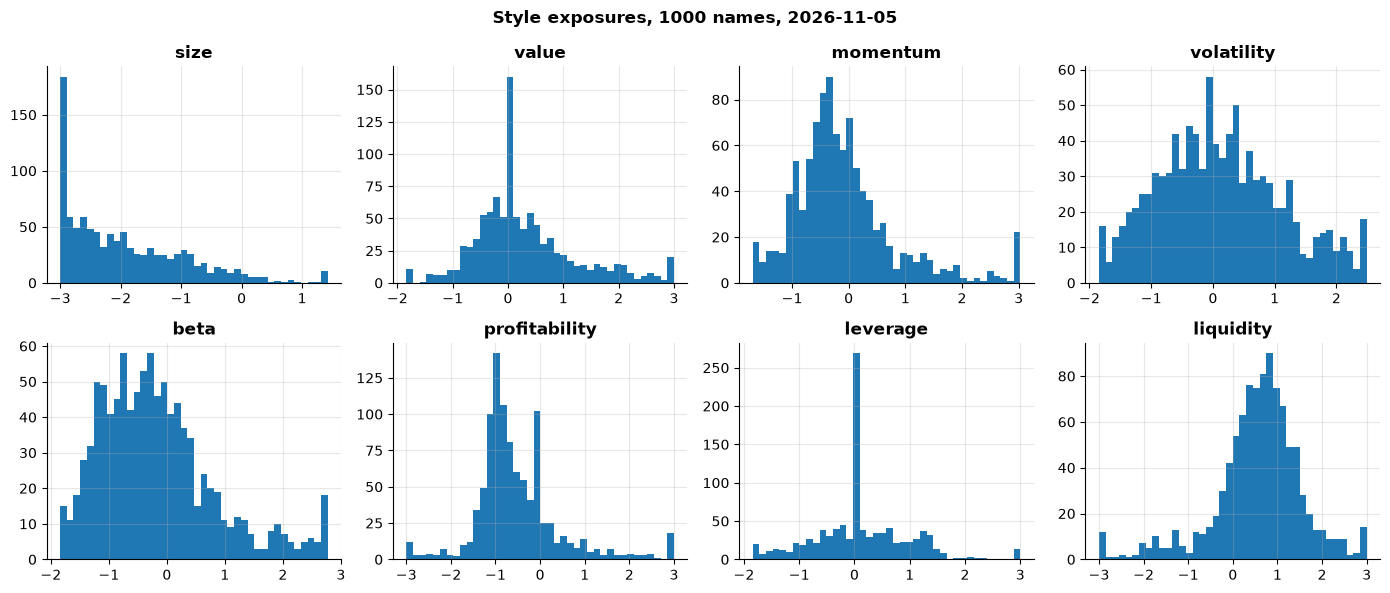

style,cap_weighted_mean,std
str,f64,f64
"""size""",0.0,0.9854
"""value""",-0.0,0.9224
"""momentum""",0.0,0.9031
"""volatility""",-0.0,1.0
"""beta""",0.0,0.9951
"""profitability""",-0.0,0.9551
"""leverage""",0.0,0.8593
"""liquidity""",-0.0,0.993


In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, s in zip(axes.flat, STYLES, strict=True):
    ax.hist(ex[s], bins=40)
    ax.set_title(s)
fig.suptitle(f"Style exposures, {ex.height} names, {last}", fontweight="bold")
fig.tight_layout()
plt.show()
w = ex["issuer_market_cap"] / ex["issuer_market_cap"].sum()
pl.DataFrame({"style": list(STYLES), "cap_weighted_mean": [float((ex[s] * w).sum()) for s in STYLES],
              "std": [float(ex[s].std()) for s in STYLES]}).with_columns(pl.col(pl.Float64).round(4))

## 3 · Factor returns

Daily cross-sectional regressions (weighted by the square root of market cap, with the
cap-weighted sector returns constrained to sum to zero so market and sectors are identifiable).
Cumulative style returns since 2011, and the regressions' explanatory power:

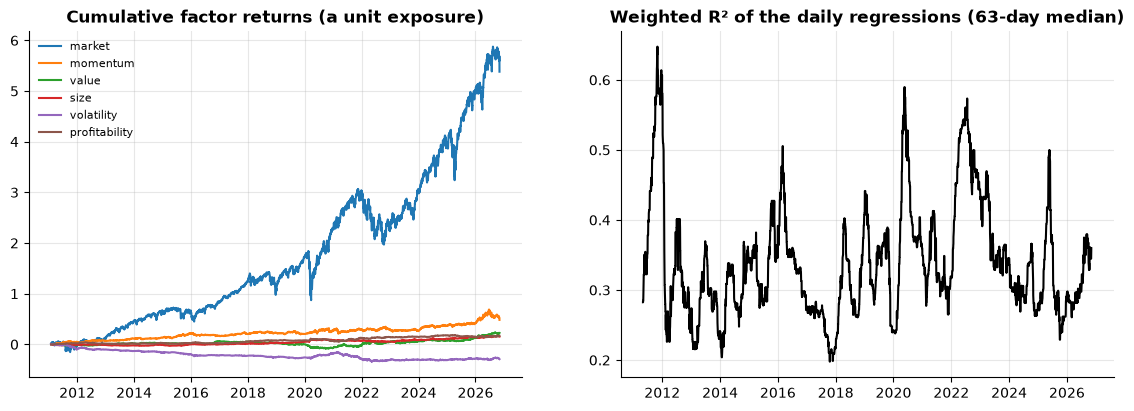

style,ann_return,ann_vol,sharpe
str,f64,f64,f64
"""size""",0.009,0.021,0.433
"""value""",0.013,0.032,0.417
"""momentum""",0.026,0.053,0.495
"""volatility""",-0.021,0.042,-0.498
"""beta""",0.006,0.067,0.086
"""profitability""",0.01,0.017,0.572
"""leverage""",0.003,0.021,0.135
"""liquidity""",0.013,0.024,0.53


In [4]:
fr = rm.factor_returns().sort("date")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for s in ["market", "momentum", "value", "size", "volatility", "profitability"]:
    axes[0].plot(fr["date"], (1 + fr[s]).cum_prod() - 1, label=s)
axes[0].set_title("Cumulative factor returns (a unit exposure)")
axes[0].legend(fontsize=8)
r2 = fr.select("date", pl.col("r2").rolling_median(63).alias("r2_median_63d"))
axes[1].plot(r2["date"], r2["r2_median_63d"], color="black")
axes[1].set_title("Weighted R² of the daily regressions (63-day median)")
plt.show()
ann = fr.select(*[pl.col(s) for s in STYLES]).mean() * 252
vol = fr.select(*[pl.col(s) for s in STYLES]).std() * np.sqrt(252)
pl.DataFrame({"style": list(STYLES), "ann_return": [ann[s][0] for s in STYLES], "ann_vol": [vol[s][0] for s in STYLES],
              "sharpe": [ann[s][0] / vol[s][0] for s in STYLES]}).with_columns(pl.col(pl.Float64).round(3))

## 4 · Covariance

`factor_cov(on)` uses factor returns up to and including that day: EWMA volatilities (half-life
84 days) times an EWMA correlation (half-life a year), scaled by the volatility regime
adjustment. Annualized factor volatilities on the latest month end and the style correlations:

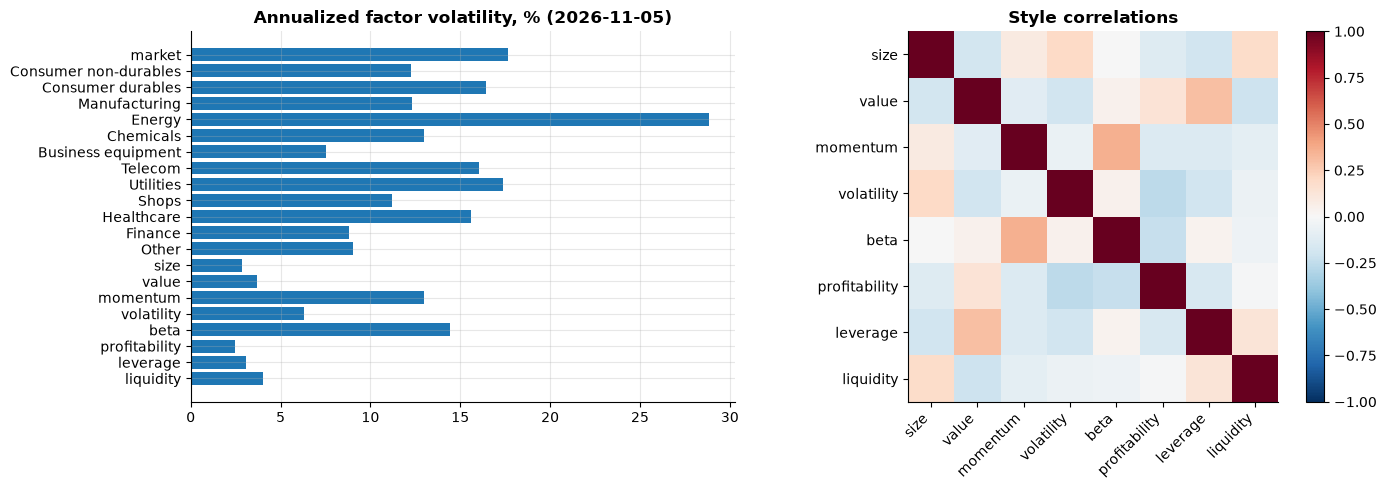

In [5]:
C = rm.factor_cov(last, annualize=True)
vols = pl.DataFrame({"factor": FACTORS, "ann_vol": [np.sqrt(C[f][i]) for i, f in enumerate(FACTORS)]})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(vols["factor"], vols["ann_vol"] * 100)
axes[0].invert_yaxis()
axes[0].set_title(f"Annualized factor volatility, % ({last})")
sty = list(STYLES)
M = np.array([[C[b][FACTORS.index(a)] for b in sty] for a in sty])
sd = np.sqrt(np.diag(M))
im = axes[1].imshow(M / np.outer(sd, sd), cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(sty)), sty, rotation=45, ha="right")
axes[1].set_yticks(range(len(sty)), sty)
axes[1].set_title("Style correlations")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], fraction=0.046)
fig.tight_layout()
plt.show()

## 5 · Specific risk

The part of each name's variance the factors do not explain: an EWMA of squared residuals
(half-life 84 days), shrunk 30% toward the cap-weighted mean of its size decile, and that mean
alone for names with fewer than 42 residuals. Smaller companies have more of it:

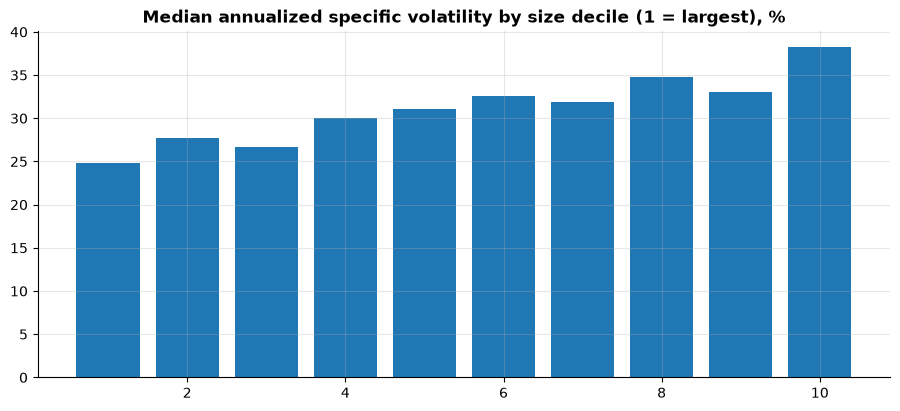

size_decile,spec_vol,names,fallback
f64,f64,u32,u32
1.0,0.247799,100,0
2.0,0.277294,100,0
3.0,0.267114,100,1
4.0,0.299897,100,0
5.0,0.31038,100,0
6.0,0.325498,100,0
7.0,0.318444,100,0
8.0,0.348171,100,0
9.0,0.330789,100,2


In [6]:
sv = rm.specific_var(last).join(ex.select("security_id", "issuer_market_cap"), on="security_id")
sv = sv.with_columns((pl.col("spec_var") * 252).sqrt().alias("spec_vol"),
                     (pl.col("issuer_market_cap").rank("ordinal", descending=True) * 10 / pl.len()).ceil().clip(1, 10).alias("size_decile"))
dec = sv.group_by("size_decile").agg(pl.col("spec_vol").median(), pl.len().alias("names"), (pl.col("n_obs") < 42).sum().alias("fallback")).sort("size_decile")
fig, ax = plt.subplots()
ax.bar(dec["size_decile"], dec["spec_vol"] * 100)
ax.set_title("Median annualized specific volatility by size decile (1 = largest), %")
plt.show()
dec

## 6 · Forecast against realized risk

Two test portfolios made from the model's own exposures each month end: an equal-weighted long
book of the 100 largest names, and a long-short book long the top momentum quintile and short
the bottom one. `predict` gives the forecast volatility from that month's model; `bias` holds the
weights over the following month and compares. The bias statistic (root mean of squared
standardized returns) is about one when the forecasts are right.

predict + bias for both portfolios: 5.17 s


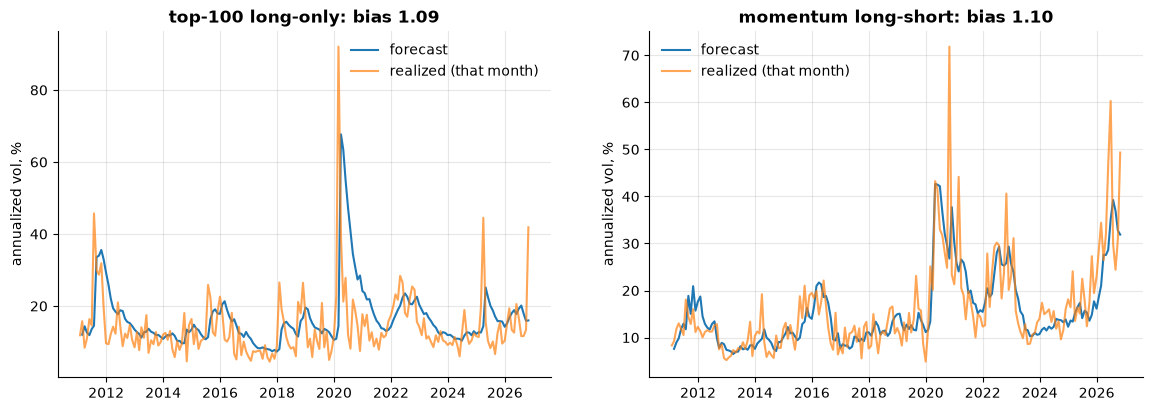

portfolio,bias_overall,bias_2020,bias_last_3y
str,f64,f64,f64
"""top-100 long-only""",1.09,1.99,1.02
"""momentum long-short""",1.1,1.22,1.24


In [7]:
allx = rm.exposures()
top100 = (allx.sort("date", "issuer_market_cap", descending=[False, True]).group_by("date", maintain_order=True).head(100)
          .with_columns((1 / pl.len().over("date")).alias("weight")).select("date", "security_id", "weight"))
q = allx.with_columns(((pl.col("momentum").rank("ordinal").over("date") - 0.5) / pl.len().over("date")).alias("pct"))
mom = (q.filter((pl.col("pct") > 0.8) | (pl.col("pct") < 0.2))
       .with_columns(pl.when(pl.col("pct") > 0.8).then(1).otherwise(-1).alias("leg"))
       .with_columns((pl.col("leg") / pl.len().over("date", "leg")).alias("weight")).select("date", "security_id", "weight"))
with timed("predict + bias for both portfolios"):
    books = {"top-100 long-only": top100, "momentum long-short": mom}
    bias = {name: rm.bias(w) for name, w in books.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for ax, (name, b) in zip(axes, bias.items(), strict=True):
    ax.plot(b["date"], b["forecast_vol"] * 100, label="forecast")
    ax.plot(b["date"], b["realized_vol"] * 100, label="realized (that month)", alpha=0.7)
    ax.set_title(f"{name}: bias {bias_stat(b):.2f}")
    ax.set_ylabel("annualized vol, %")
    ax.legend()
plt.show()
pl.DataFrame({"portfolio": list(bias), "bias_overall": [bias_stat(b) for b in bias.values()],
              "bias_2020": [bias_stat(b.filter(pl.col("date").dt.year() == 2020)) for b in bias.values()],
              "bias_last_3y": [bias_stat(b.filter(pl.col("date") >= b["date"].max().replace(year=b["date"].max().year - 3))) for b in bias.values()]}
             ).with_columns(pl.col(pl.Float64).round(2))

## 7 · Attribution

`attribute` splits each day's return of a held book into factor contributions (exposure times
factor return) and the specific remainder. The momentum book, cumulated:

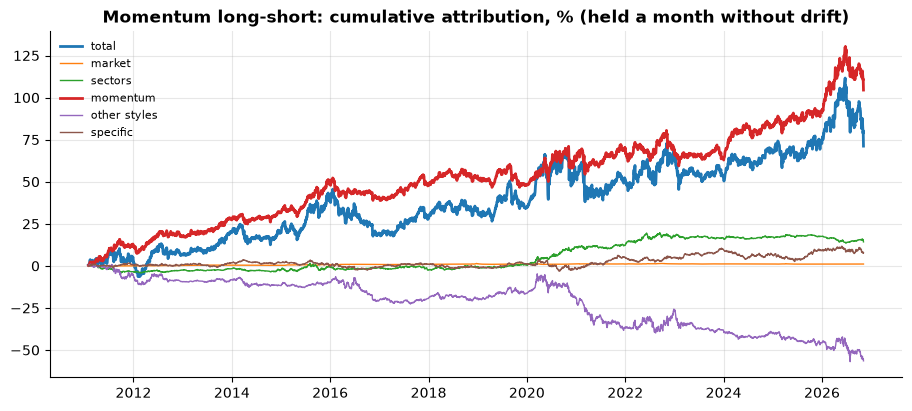

factor,exposure,factor_vol,contribution
str,f64,f64,f64
"""momentum""",2.41,0.13,0.82
"""beta""",0.64,0.144,0.14
"""Energy""",0.09,0.289,0.014
"""specific""",null,null,0.012
"""Other""",-0.07,0.09,0.005
"""Manufacturing""",0.04,0.123,0.004
"""leverage""",-0.245,0.031,0.003
"""Consumer durables""",-0.035,0.164,0.002


In [8]:
att = rm.attribute(mom).sort("date")
sectors = FACTORS[1:13]
cum = att.select("date", pl.col("total").cum_sum(), pl.col("market").cum_sum(),
                 pl.sum_horizontal(sectors).cum_sum().alias("sectors"), pl.col("momentum").cum_sum(),
                 pl.sum_horizontal([s for s in STYLES if s != "momentum"]).cum_sum().alias("other styles"),
                 pl.col("specific").cum_sum())
fig, ax = plt.subplots()
for c in cum.columns[1:]:
    ax.plot(cum["date"], cum[c] * 100, label=c, lw=2 if c in ("total", "momentum") else 1)
ax.set_title("Momentum long-short: cumulative attribution, % (held a month without drift)")
ax.legend(fontsize=8)
plt.show()
rm.contributions(mom.filter(pl.col("date") == last), on=last).sort("contribution", descending=True).head(8).with_columns(pl.col(pl.Float64).round(3))

## 8 · The built-in checks

`queen check` runs the same kind of tests: the market factor against SPY, the regressions'
explanatory power, and the bias statistic on test portfolios.

In [9]:
with timed("rm.check()"):
    checks = rm.check()
pl.DataFrame(checks, schema=["check", "passed", "detail"], orient="row")

rm.check(): 9.40 s


check,passed,detail
str,bool,str
"""market factor tracks SPY (dail…",true,"""0.990"""
"""median daily R2 between 0.15 a…",true,"""0.327"""
"""forecast risk cap-weighted uni…",true,"""1.08; forecast 16.8%, realized…"
"""forecast risk random 50+50 lon…",true,"""1.06; forecast 6.0%, realized …"
"""forecast risk random 2+2 long-…",true,"""0.99; forecast 29.1%, realized…"
"""forecast risk size top minus b…",true,"""1.06; forecast 7.8%, realized …"
"""forecast risk value top minus …",true,"""1.15; forecast 13.8%, realized…"
"""forecast risk momentum top min…",true,"""1.11; forecast 15.9%, realized…"
"""forecast risk volatility top m…",true,"""1.09; forecast 19.1%, realized…"


## Takeaways
- Exposures are point in time (month ends from point-in-time signals) and cap-weighted neutral,
  so the market factor is the cap-weighted market and styles are tilts against it.
- Factor returns, covariance and specific risk at a date use data up to that date only.
- The bias statistics on test books are close to one, with the usual understatement in
  2020-style regime changes that the volatility regime adjustment only partly catches.
- Attribution and contributions make a book's risk and return legible by factor; the optimizer
  in `01_optimizer.ipynb` constrains exactly those exposures.